# Stage 00 capstone: audit a Gaussian computation

## 1. Introduction and learning objectives

Build a small, defensible numerical audit rather than a general-purpose statistics package. Estimate Gaussian summaries, evaluate a stable log-likelihood, independently check a mean gradient, and investigate precision and conditioning. Separate mathematical correctness, code correctness, and the claim supported by an experiment.

Read the [project instructions](README.md) and use the [report template](report-template.md). All required data are generated locally. Answer cells start blank. The displayed references are a review aid; demonstrations do not call them. A fast audit can be run in minutes; the longer study session is for reasoning, implementation, and reporting.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 00.P.01 — Declare the model and the evidence

**Type:** Conceptual · **Answer:** Markdown

Write an audit protocol for iid rows X∈R^(n×d) modeled by N(μ,Σ). Distinguish the population distribution, estimated parameters, numerical verification, and held-out assessment. State when you would reject the model assumptions.

**Expected outcome:** a short protocol with data/split seeds and four separate mastery claims.

**Your response to Exercise 00.P.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.01**

An accurate likelihood implementation can still be a poor model of dependent or heavy-tailed observations.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.01**

One suitable protocol fixes d, seeds, dtype, and sample counts before generation; estimates summaries from training rows; verifies formulas on a hand example and gradients at non-optimal μ with fixed positive-definite Σ; then assesses held-out likelihood and diagnostics. Explain the iid Gaussian assumptions, implement the estimator and solve, verify derivatives and shapes independently, and evaluate sensitivity and model limits. Outliers, dependence, multimodality, or singular feature structure require explicit reconsideration.

</details>

## 2. Prerequisites and mathematical foundations

Complete the three Stage 00 chapters or pass their diagnostics. Rows are observations, μ has shape (d,), and Σ has shape (d,d). Mean negative log-likelihood is

$$L(\mu,\Sigma)=\frac d2\log(2\pi)+\frac12\log\det\Sigma+
\frac1{2n}\sum_i(x_i-\mu)^T\Sigma^{-1}(x_i-\mu).$$

This assumes symmetric positive-definite covariance. A positive determinant alone is insufficient: diag(−1,−1) has positive determinant and is not a covariance. A Cholesky factor Σ=CCᵀ both checks the domain and enables stable solves. Compute log determinant as 2Σ_j log C_jj, and whiten residuals by solving C u_i=x_i−μ.

## 3. Theoretical development and worked examples

With Σ fixed, differentiating the quadratic gives

$$\nabla_\mu L=\Sigma^{-1}(\mu-\bar x).$$

The 1/n average is already in x̄; multiplying by 1/n again is incorrect. This gradient is a partial derivative holding covariance fixed. Re-estimating Σ inside a finite-difference objective changes the function being checked.

For X=[(1,0),(3,2),(2,4),(4,2)], x̄=(2.5,2). The centered cross-product sum is [[5,2],[2,8]]. MLE covariance is [[1.25,.5],[.5,2]], while the unbiased covariance is [[5/3,2/3],[2/3,8/3]]. Neither denominator should be chosen implicitly.

### Exercise 00.P.02 — Derive the mean gradient

**Type:** Mathematical · **Answer:** Markdown

Derive the mean gradient from the displayed objective with fixed symmetric Σ. Give its shape and identify where the observation average occurs.

**Expected outcome:** a differential or coordinate derivation, including the covariance's symmetry.

**Your response to Exercise 00.P.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.02**

For symmetric M, d(rᵀMr)=2rᵀM dr; here dr=−dμ.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.02**

The quadratic differential is −n⁻¹Σ_i(x_i−μ)ᵀΣ⁻¹dμ. Thus the gradient is −Σ⁻¹(x̄−μ)=Σ⁻¹(μ−x̄), shape (d,). The constant and log determinant have zero μ derivative when covariance is fixed. The row average enters once through x̄; symmetry makes the two quadratic contributions equal.

</details>

### Exercise 00.P.03 — Establish a hand oracle

**Type:** Numerical · **Answer:** Markdown

Using the four rows above, μ=(0,0), and Σ=I, compute mean negative log-likelihood and mean gradient. Also calculate both covariance estimates.

**Expected outcome:** exact expressions sufficient to test your implementation without calling it for the expected values.

**Your response to Exercise 00.P.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.03**

The squared row norms are 1,13,20,20.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.03**

The mean squared norm is 54/4=13.5. With d=2 and log determinant zero, L=log(2π)+6.75, approximately 8.5878770664. The gradient is (−2.5,−2). The two covariance estimates are the matrices derived above. Keeping this scalar oracle separate from the implementation helps catch shared errors in scaling or centering.

</details>

## 4. Guided exercises

The required workload is n=512 training rows and n=256 held-out rows, d=3, float64. Use mean (1,−2,.5) and covariance [[2,.4,0],[.4,1,.2],[0,.2,.5]]. The provided plot is a data inspection, not a completed estimator. Keep held-out rows out of parameter estimation.

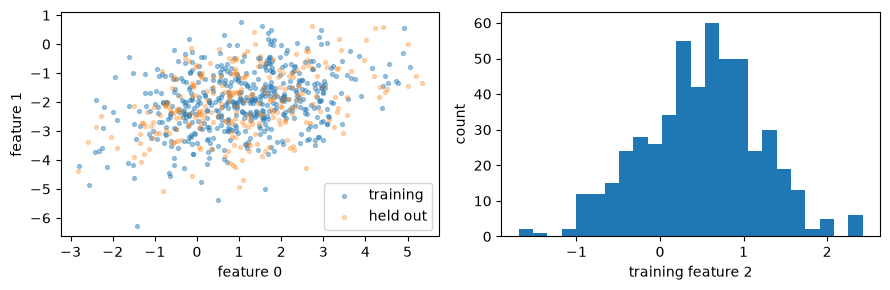

In [2]:
data_rng = np.random.default_rng(2026)
population_mean = np.array([1., -2., .5])
population_covariance = np.array([[2., .4, 0.], [.4, 1., .2], [0., .2, .5]])
train_rows = data_rng.multivariate_normal(population_mean, population_covariance, size=512)
heldout_rows = np.random.default_rng(2027).multivariate_normal(population_mean, population_covariance, size=256)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].scatter(train_rows[:, 0], train_rows[:, 1], s=8, alpha=.4, label="training")
axes[0].scatter(heldout_rows[:, 0], heldout_rows[:, 1], s=8, alpha=.3, label="held out")
axes[0].set(xlabel="feature 0", ylabel="feature 1"); axes[0].legend()
axes[1].hist(train_rows[:, 2], bins=24)
axes[1].set(xlabel="training feature 2", ylabel="count")
fig.tight_layout(); plt.show()

### Exercise 00.P.04 — Specify acceptance criteria before running

**Type:** Conceptual · **Answer:** Markdown

List checks for shape, covariance denominator, positive definiteness, finite loss, gradient accuracy, and input mutation. Choose tolerances and at least one intentional failure.

**Expected outcome:** a checklist that cannot pass merely because a training loss decreased.

**Your response to Exercise 00.P.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.04**

Check non-optimal parameters and one-dimensional data as well as the standard dataset.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.04**

A suitable gate includes the four-row oracle; d=1 and d=3 shape checks; equality of unbiased covariance with the MLE multiplied by n/(n−1); rejection of nonsymmetric, singular, or indefinite covariance; finite loss; and coordinate finite differences at multiple non-optimal μ with about 1e−6 relative/absolute agreement in float64. Verify inputs remain unchanged. Report absolute errors near a zero gradient. A decreasing loss checks an optimization behavior but does not isolate any of these contracts.

</details>

## 5. Implementation challenges

### Exercise 00.P.05 — Estimate both Gaussian summaries

**Type:** Programming · **Answer:** Code

Implement `summary_estimates(X)` returning mean, MLE covariance, and unbiased covariance for finite (n,d) input with n≥2 and d≥1.

**Expected outcome:** the four-row oracle and an explicit note that a computed covariance may be singular.

In [ ]:
# Your code for Exercise 00.P.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.05**

Share the centered cross-product numerator, then divide by n or n−1.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.05**

An estimator may return a singular covariance legitimately. Likelihood evaluation has a stricter positive-definiteness contract; do not silently add a diagonal term without documenting a changed model.

~~~python
def summary_estimates(X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) < 2 or X.shape[1] == 0 or not np.isfinite(X).all():
        raise ValueError("at least two finite rows required")
    mean = X.mean(axis=0)
    centered = X - mean
    numerator = centered.T @ centered
    return mean, numerator / len(X), numerator / (len(X) - 1)
~~~

</details>

### Exercise 00.P.06 — Evaluate a stable likelihood and gradient

**Type:** Programming · **Answer:** Code

Implement `gaussian_nll(X, mu, covariance)` with the displayed mean objective. Validate shapes, finiteness, symmetry and positive definiteness. Use a Cholesky factor and solves, not an inverse or determinant product. Return loss and mean gradient.

**Expected outcome:** agreement with the hand oracle, including rejection of diag(−1,−1).

In [ ]:
# Your code for Exercise 00.P.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.06**

Whiten all residual columns in one solve. Solve twice for Σ⁻¹(μ−x̄).

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.06**

Symmetry is checked with a tight tolerance and the accepted matrix is symmetrized to remove tiny representational asymmetry. Cholesky then rejects a singular or indefinite covariance. This policy is part of the contract.

~~~python
def gaussian_nll(X, mu, covariance):
    X, mu, covariance = (np.asarray(a, dtype=float) for a in (X, mu, covariance))
    if X.ndim != 2 or len(X) == 0 or X.shape[1] == 0:
        raise ValueError("nonempty observation matrix required")
    d = X.shape[1]
    if mu.shape != (d,) or covariance.shape != (d, d):
        raise ValueError("parameter shape mismatch")
    if not all(np.isfinite(a).all() for a in (X, mu, covariance)):
        raise ValueError("finite inputs required")
    if not np.allclose(covariance, covariance.T, rtol=1e-12, atol=1e-12):
        raise ValueError("symmetric covariance required")
    C = np.linalg.cholesky((covariance + covariance.T) / 2)
    whitened = np.linalg.solve(C, (X - mu).T)
    loss = d / 2 * np.log(2 * np.pi) + np.log(np.diag(C)).sum() + .5 * np.mean(np.sum(whitened**2, axis=0))
    gradient = np.linalg.solve(C.T, np.linalg.solve(C, mu - X.mean(axis=0)))
    return float(loss), gradient
~~~

</details>

### Exercise 00.P.07 — Check the gradient with an independent objective

**Type:** Programming · **Answer:** Code

Implement `audit_mean_gradient(X, mu, covariance, step=1e-5)`. Use your gradient but independently calculate the scalar objective through slogdet and a general solve. Keep covariance fixed. Return analytic gradient, numeric gradient, maximum absolute discrepancy, and normalized discrepancy.

**Expected outcome:** agreement at two non-optimal means and a warning about checks at a stationary point only.

In [ ]:
# Your code for Exercise 00.P.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.07**

Use copied perturbed means. Normalize by max(1, ||analytic||, ||numeric||), and also report absolute discrepancy.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.07**

This depends on `gaussian_nll`. Its initial call validates covariance. The separate objective has a different algebraic path, reducing shared-implementation errors, though the hand oracle remains necessary.

~~~python
def audit_mean_gradient(X, mu, covariance, step=1e-5):
    X, mu, covariance = (np.array(a, dtype=float, copy=True) for a in (X, mu, covariance))
    if not np.isfinite(step) or step <= 0:
        raise ValueError("positive finite step required")
    _, analytic = gaussian_nll(X, mu, covariance)
    def independent(candidate):
        residual = X - candidate
        _, logdet = np.linalg.slogdet(covariance)
        quadratic = np.sum(residual * np.linalg.solve(covariance, residual.T).T, axis=1)
        return .5 * (X.shape[1] * np.log(2 * np.pi) + logdet + quadratic.mean())
    numeric = np.empty_like(mu)
    for j in range(len(mu)):
        plus, minus = mu.copy(), mu.copy()
        plus[j] += step
        minus[j] -= step
        numeric[j] = (independent(plus) - independent(minus)) / (2 * step)
    difference = analytic - numeric
    relative = np.linalg.norm(difference) / max(1., np.linalg.norm(analytic), np.linalg.norm(numeric))
    return analytic, numeric, float(np.max(np.abs(difference))), float(relative)
~~~

</details>

## 6. Experiments and visualizations

### Exercise 00.P.08 — Run a reproducible audit and held-out check

**Type:** Experimental · **Answer:** Code

Use the provided training and held-out rows. Fit only training summaries, audit the gradient at μ̂+(.2,−.1,.3) holding Σ̂ fixed, and compare train and held-out mean NLL. Record shapes, seeds, tolerances, elapsed time, and memory metric.

**Expected outcome:** actual results, independently verified covariance, and no guarantee that one particular ordering of train/test loss must occur.

In [ ]:
# Your code for Exercise 00.P.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.08**

Compare covariance against np.cov with explicit ddof. Time the numerical work separately from plotting.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.08**

This depends on all three project implementations and the provided data demonstration. The held-out likelihood evaluates one fitted model. It is not evidence that all Gaussian assumptions are correct.

~~~python
from time import perf_counter
start = perf_counter()
mu_hat, covariance_mle, covariance_unbiased = summary_estimates(train_rows)
np.testing.assert_allclose(covariance_unbiased, np.cov(train_rows, rowvar=False, ddof=1))
audit = audit_mean_gradient(train_rows, mu_hat + [.2, -.1, .3], covariance_mle)
train_loss = gaussian_nll(train_rows, mu_hat, covariance_mle)[0]
heldout_loss = gaussian_nll(heldout_rows, mu_hat, covariance_mle)[0]
print("gradient absolute/normalized error", audit[2:])
print("train and held-out NLL", train_loss, heldout_loss)
print("numerical elapsed seconds", perf_counter() - start)
plt.bar(["training", "held out"], [train_loss, heldout_loss])
plt.ylabel("mean negative log-likelihood"); plt.show()
~~~

</details>

### Exercise 00.P.09 — Probe a nearly singular covariance

**Type:** Experimental · **Answer:** Code

For covariance diag(1, ε), ε∈{1e−2,1e−5,1e−8}, evaluate the likelihood of rows [(0,0),(0,1)] at μ=0. Compare float32 and float64 Cholesky/solve paths, holding the mathematical inputs fixed. Report condition number and whether the large loss is a bug or model sensitivity.

**Expected outcome:** measurements with an independent scalar formula, plus an exact-singularity failure case.

In [ ]:
# Your code for Exercise 00.P.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.09**

The mean quadratic contribution is 1/(4ε); the log determinant contribution is log(ε)/2.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.09**

Large loss is expected when a model assigns tiny variance to a direction containing residuals. This reference preserves dtype explicitly; the project's general API intentionally promotes to float64. Float32 is not guaranteed to fail on this diagonal example, so report actual differences.

~~~python
for epsilon in (1e-2, 1e-5, 1e-8):
    expected = np.log(2 * np.pi) + .5 * np.log(epsilon) + 1 / (4 * epsilon)
    for dtype in (np.float32, np.float64):
        covariance = np.diag(np.array([1., epsilon], dtype=dtype))
        rows = np.array([[0., 0.], [0., 1.]], dtype=dtype)
        C = np.linalg.cholesky(covariance)
        white = np.linalg.solve(C, rows.T)
        value = np.log(2 * np.pi) + np.log(np.diag(C)).sum() + .5 * np.mean(np.sum(white**2, axis=0))
        print(epsilon, dtype.__name__, np.linalg.cond(covariance), value, abs(value - expected))
try:
    gaussian_nll([[0., 0.]], [0., 0.], np.diag([1., 0.]))
except np.linalg.LinAlgError:
    print("exact singularity correctly rejected")
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 00.P.10 — Reject an invalid verification protocol

**Type:** Critical · **Answer:** Markdown

An audit uses only μ=x̄, recomputes covariance on every perturbed mean, and adds 1e−3 I whenever Cholesky fails without reporting it. Explain the three problems and repair the protocol.

**Expected outcome:** separate repairs for an uninformative test point, a changed objective, and an undocumented model change.

**Your response to Exercise 00.P.10**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.10**

Every finite-difference evaluation must implement the same function whose gradient you derived.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.10**

At x̄ the true gradient is zero, so an implementation that always returns zero can pass. Add non-optimal means and coordinate checks. Re-estimating covariance changes the scalar objective and invalidates the fixed-covariance derivative comparison. Adding diagonal jitter changes the likelihood model; either reject the covariance or document a regularization policy and evaluate the altered model explicitly. Preserve failure evidence in the report.

</details>

## 8. Review questions and knowledge checks

### Exercise 00.P.11 — Sign off each mastery claim

**Type:** Conceptual · **Answer:** Markdown

State what evidence demonstrates explain, implement, verify, and evaluate for this project. What would remain unsupported even after every numerical check passes?

**Expected outcome:** four evidence references and a bounded conclusion.

**Your response to Exercise 00.P.11**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.P.11**

Correct code does not prove an iid Gaussian data-generating process.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.P.11**

Explanation is supported by a derivation and assumptions; implementation by the estimator and stable likelihood; verification by hand values, independent gradients, shapes, and failure tests; evaluation by held-out measurements and sensitivity analysis. Passing these checks does not establish population Gaussianity, independence, robustness to a new population, or calibrated uncertainty for arbitrary data. A completed report names those limits rather than claiming universal correctness.

</details>

## 9. Summary and next learning steps

Finish the report with actual measurements and reproducible commands. Keep learner implementations on your study branch. Continue to [Stage 01 linear regression](../../notebooks/01-ml-fundamentals/linear-regression.ipynb), carrying forward the same shape, objective, stability, and independent-check discipline.